# Amplitude preprocessing

Process each accepted, non-excluded trial and receiver separately. Matrices retain shape `(packets, subcarriers)`, signed physical subcarrier indices, capture timestamps, phases, and invalid-sample masks. Raw recordings are not changed.

The centered Hampel filter uses a 100 ms window, at least five valid samples, and a threshold of five scaled MADs, as in the exploration notebook. Min–max scaling is fitted independently to each subcarrier over the entire masked recording, before Hampel filtering. This exploratory choice uses future samples: for model evaluation, fit scaling on training data only and use an appropriate causal preprocessing window.

Polars handles recording selection and projected Parquet reads. Rust decodes HE20 I/Q batches, aligns physical subcarriers, masks invalid samples, normalizes amplitudes, and filters outliers in parallel. Unused phase calibration is skipped. A bounded background writer overlaps lossless NPZ compression with the next recording. Build or update the extension before starting the kernel:

```bash
uv sync --inexact --extra analysis --reinstall-package radio-fall-detection
```

See [the preprocessing implementation and benchmark](../../docs/amplitude-preprocessing.md) for verification and timing limits.

In [15]:
from pathlib import Path
import os
import sys

import numpy as np
import polars as pl
from IPython.display import display

PROJECT_ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "src" / "fall_detection").is_dir()
)
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from fall_detection.analysis.amplitude_pipeline import (
    AmplitudePacketReader, load_amplitude_session, prepare_recording, preprocess_dataset,
)

SESSION_ID = "20261104T081805521126Z"
RAW_DIR = PROJECT_ROOT / "data" / "raw" / "sessions" / SESSION_ID
PARQUET_DIR = PROJECT_ROOT / "data" / "interim" / "parquet" / SESSION_ID
OUTPUT_DIR = Path(os.environ.get(
    "AMPLITUDE_OUTPUT_DIR",
    PROJECT_ROOT / "data" / "interim" / "amplitude_preprocessed_v3" / SESSION_ID,
))
# Optional limit for a small exploratory run. Omit the environment variable
# to process every selected recording.
MAX_RECORDINGS = int(os.environ["AMPLITUDE_MAX_RECORDINGS"]) if "AMPLITUDE_MAX_RECORDINGS" in os.environ else None
HAMPEL_WINDOW_SECONDS = 0.1
HAMPEL_MIN_PERIODS = 5
HAMPEL_THRESHOLD = 5.0

session = load_amplitude_session(RAW_DIR, PARQUET_DIR, progress=print)
attempts = session.attempts
selected = attempts.filter(
    (pl.col("status") == "accepted") & (pl.col("inclusion") != "exclude").fill_null(True)
)
recordings = (
    selected.explode("receiver_ids")
    .drop_nulls("receiver_ids")
    .sort(["trial_ordinal", "attempt", "receiver_ids"])
)
if MAX_RECORDINGS is not None:
    if MAX_RECORDINGS < 1:
        raise ValueError("AMPLITUDE_MAX_RECORDINGS must be positive.")
    recordings = recordings.head(MAX_RECORDINGS)
if recordings.is_empty():
    raise ValueError("No accepted, non-excluded receiver recordings found.")
print(f"Processing {len(recordings)} receiver recordings from {SESSION_ID}.")
print(f"Output: {OUTPUT_DIR}")

Processing 928 receiver recordings from 20261104T081805521126Z.
Output: /home/khaelano/Projects/radio-fall-detection/data/interim/amplitude_preprocessed_v3/20261104T081805521126Z


In [16]:
from fall_detection.analysis.amplitude import (
    hampel_subcarriers as native_hampel_subcarriers,
)


def hampel_subcarriers(amplitude, times):
    """Use the native filter with this notebook's recorded parameters."""
    return native_hampel_subcarriers(
        amplitude, times,
        window_seconds=HAMPEL_WINDOW_SECONDS,
        min_periods=HAMPEL_MIN_PERIODS,
        threshold=HAMPEL_THRESHOLD,
    )


## Inspect one recording

Choose one recording and subcarriers below. Run the following cells in order to see the output of masking, normalization, and Hampel filtering before processing the full dataset.

In [17]:
import matplotlib.pyplot as plt

VISUALIZE_RECORDING_INDEX = 0
# Use None for five evenly spaced valid subcarriers, or specify physical indices.
SUBCARRIERS_TO_PLOT = None

if not 0 <= VISUALIZE_RECORDING_INDEX < len(recordings):
    raise IndexError("VISUALIZE_RECORDING_INDEX is outside the recordings table.")
chosen = recordings.row(VISUALIZE_RECORDING_INDEX, named=True)
plot_reader = AmplitudePacketReader(session.path / "packets.parquet")
try:
    plot_signal = prepare_recording(plot_reader.read(
        chosen["attempt_key"], chosen["receiver_ids"],
    ))
finally:
    plot_reader.close()
print(f"{chosen['scenario_id']} | trial {plot_signal.metadata['attempt_id'][0]} | {chosen['receiver_ids']}")


stand-to-walk__start_no_direction__end_front | trial 001/02 | rx-1


### 1. Mask invalid amplitudes

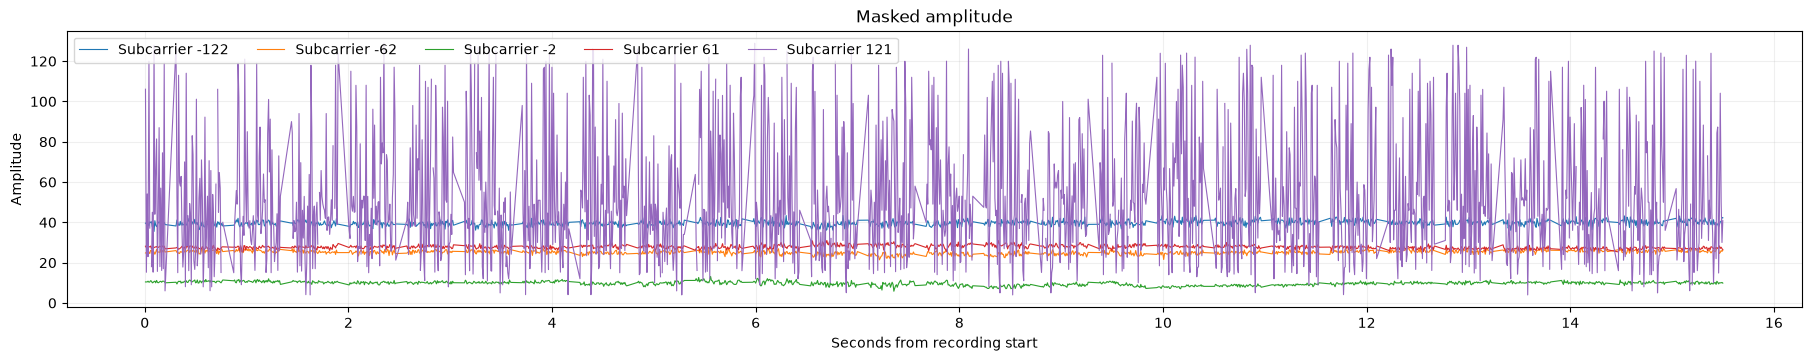

In [18]:
plot_masked = plot_signal.masked
plot_valid = np.isfinite(plot_masked)

available = np.flatnonzero(np.isfinite(plot_masked).any(axis=0))
if not len(available):
    raise ValueError("The selected recording has no valid subcarrier samples.")
if SUBCARRIERS_TO_PLOT is None:
    positions = available[np.linspace(0, len(available) - 1, min(5, len(available)), dtype=int)]
else:
    positions = []
    for subcarrier in SUBCARRIERS_TO_PLOT:
        matches = np.flatnonzero(plot_signal.subcarriers == subcarrier)
        if len(matches) != 1 or not np.isfinite(plot_masked[:, matches[0]]).any():
            raise ValueError(f"Subcarrier {subcarrier} is missing or has no valid samples.")
        positions.append(matches[0])
    if not positions:
        raise ValueError("Choose at least one subcarrier.")

fig, ax = plt.subplots(figsize=(18, 3.5), layout="constrained")
for position in positions:
    ax.plot(plot_signal.time_seconds, plot_masked[:, position],
            label=f"Subcarrier {plot_signal.subcarriers[position]}", linewidth=0.8)
ax.set(title="Masked amplitude", xlabel="Seconds from recording start", ylabel="Amplitude")
ax.legend(ncol=min(5, len(positions)))
ax.grid(alpha=0.2)
plt.show()

### 2. Normalize each subcarrier to −1 to 1

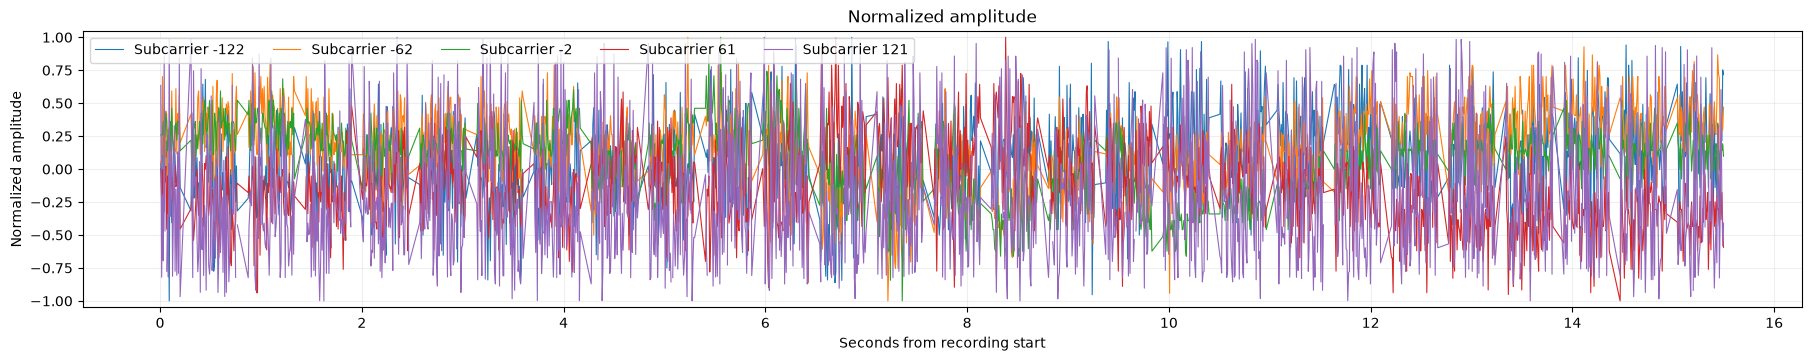

In [19]:
plot_normalized, plot_lower, plot_upper = (plot_signal.normalized, plot_signal.lower, plot_signal.upper)

fig, ax = plt.subplots(figsize=(18, 3.5), layout="constrained")
for position in positions:
    ax.plot(plot_signal.time_seconds, plot_normalized[:, position],
            label=f"Subcarrier {plot_signal.subcarriers[position]}", linewidth=0.8)
ax.set(title="Normalized amplitude", xlabel="Seconds from recording start",
       ylabel="Normalized amplitude", ylim=(-1.05, 1.05))
ax.legend(ncol=min(5, len(positions)))
ax.grid(alpha=0.2)
plt.show()

### 3. Apply the Hampel filter to each normalized subcarrier

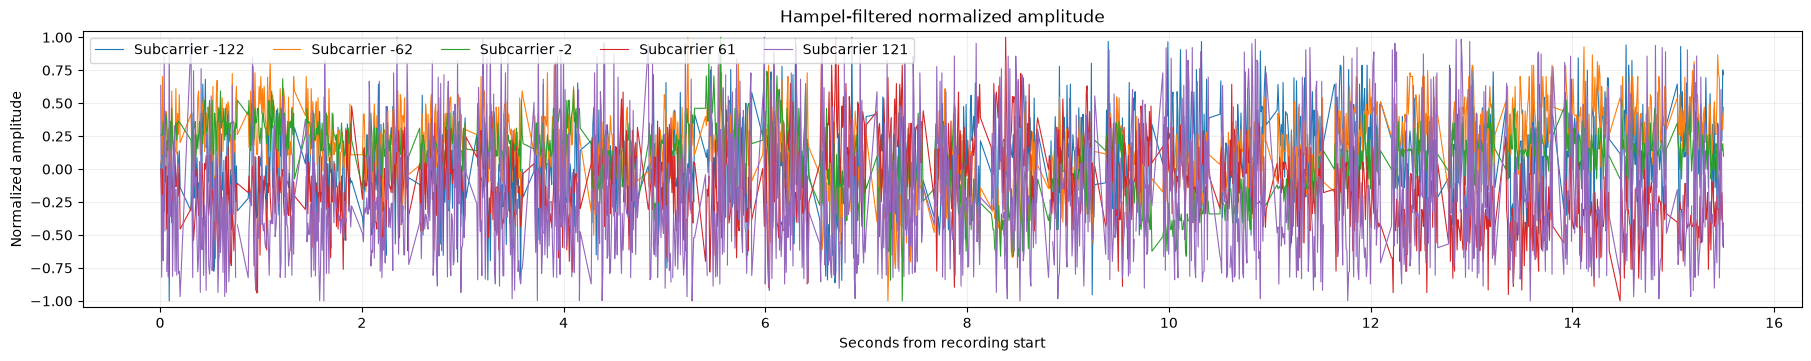

Replaced 2,105 subcarrier values in this recording.


In [20]:
plot_filtered, plot_replaced = hampel_subcarriers(plot_normalized, plot_signal.time_seconds)

fig, ax = plt.subplots(figsize=(18, 3.5), layout="constrained")
for position in positions:
    ax.plot(plot_signal.time_seconds, plot_filtered[:, position],
            label=f"Subcarrier {plot_signal.subcarriers[position]}", linewidth=0.8)
ax.set(title="Hampel-filtered normalized amplitude", xlabel="Seconds from recording start",
       ylabel="Normalized amplitude", ylim=(-1.05, 1.05))
ax.legend(ncol=min(5, len(positions)))
ax.grid(alpha=0.2)
plt.show()
print(f"Replaced {plot_replaced.sum():,} subcarrier values in this recording.")

## Process and save the dataset

Run the next cell to apply the same steps to every selected trial and receiver.

In [21]:
from time import perf_counter

# Deflate level 1 keeps the same NPZ arrays while reducing compression cost.
NPZ_COMPRESSION_LEVEL = 1
started = perf_counter()
summary = preprocess_dataset(
    session, recordings, OUTPUT_DIR,
    window_seconds=HAMPEL_WINDOW_SECONDS,
    min_periods=HAMPEL_MIN_PERIODS,
    threshold=HAMPEL_THRESHOLD,
    compression_level=NPZ_COMPRESSION_LEVEL,
)
elapsed = perf_counter() - started
display(summary.head())
print(f"Saved {len(summary)} files in {elapsed:.2f} s; "
      f"{summary['hampel_replaced'].sum():,} subcarrier values filtered.")


Processed 20/928 recordings
Processed 40/928 recordings
Processed 60/928 recordings
Processed 80/928 recordings
Processed 100/928 recordings
Processed 120/928 recordings
Processed 140/928 recordings
Processed 160/928 recordings
Processed 180/928 recordings
Processed 200/928 recordings
Processed 220/928 recordings
Processed 240/928 recordings
Processed 260/928 recordings
Processed 280/928 recordings
Processed 300/928 recordings
Processed 320/928 recordings
Processed 340/928 recordings
Processed 360/928 recordings
Processed 380/928 recordings
Processed 400/928 recordings
Processed 420/928 recordings
Processed 440/928 recordings
Processed 460/928 recordings
Processed 480/928 recordings
Processed 500/928 recordings
Processed 520/928 recordings
Processed 540/928 recordings
Processed 560/928 recordings
Processed 580/928 recordings
Processed 600/928 recordings
Processed 620/928 recordings
Processed 640/928 recordings
Processed 660/928 recordings
Processed 680/928 recordings
Processed 700/928 

attempt,receiver,packets,subcarriers,valid_values,hampel_replaced,output,read_seconds,prepare_seconds,hampel_seconds
str,str,i64,i64,i64,i64,str,f64,f64,f64
"""001/02""","""rx-1""",1536,245,370148,2105,"""/home/khaelano/Projects/radio-…",0.018107,0.016881,0.025625
"""001/02""","""rx-2""",1542,245,371603,2203,"""/home/khaelano/Projects/radio-…",0.014578,0.011165,0.022287
"""001/02""","""rx-3""",1527,245,367731,2449,"""/home/khaelano/Projects/radio-…",0.0134,0.014328,0.027048
"""001/02""","""rx-4""",1525,245,367495,2047,"""/home/khaelano/Projects/radio-…",0.013027,0.011321,0.019889
"""002/01""","""rx-1""",1491,245,359298,4281,"""/home/khaelano/Projects/radio-…",0.015781,0.008496,0.024445


Saved 928 files in 35.33 s; 2,454,104 subcarrier values filtered.


Each `.npz` file contains one trial and receiver. `amplitude` contains the normalized, Hampel-filtered values, while `valid` and `hampel_replaced` identify available and replaced samples. `scale_min` and `scale_max` describe scaling before filtering; constant valid subcarriers map to zero. Missing packets are not synthesized.

## Generate overlapping windows

Resample each recording at 80 Hz and generate 2, 4, and 6 second windows with 50% overlap. Interpolation across gaps longer than 25 ms remains masked. Each window is labeled with its center phase; the attempt activity label remains in its provenance.

In [22]:
from fall_detection.analysis.windows import generate_windows

WINDOW_OUTPUT_DIR = PROJECT_ROOT / "data" / "interim" / "amplitude_windows_v1" / SESSION_ID
window_counts = generate_windows(OUTPUT_DIR, WINDOW_OUTPUT_DIR, recording_paths=summary["output"].to_list())
print(window_counts)

{2: 11496, 4: 4584, 6: 2238}


## Compare resampling methods

Compare the same saved window and physical subcarrier using linear interpolation, nearest neighbor, and previous-sample hold. Points show the original irregular samples after amplitude preprocessing. All methods use the same 80 Hz grid and require valid adjacent samples no more than 25 ms apart; gaps remain empty. The linear series is checked against the saved window. These are exploratory comparisons and do not apply an anti-alias filter.

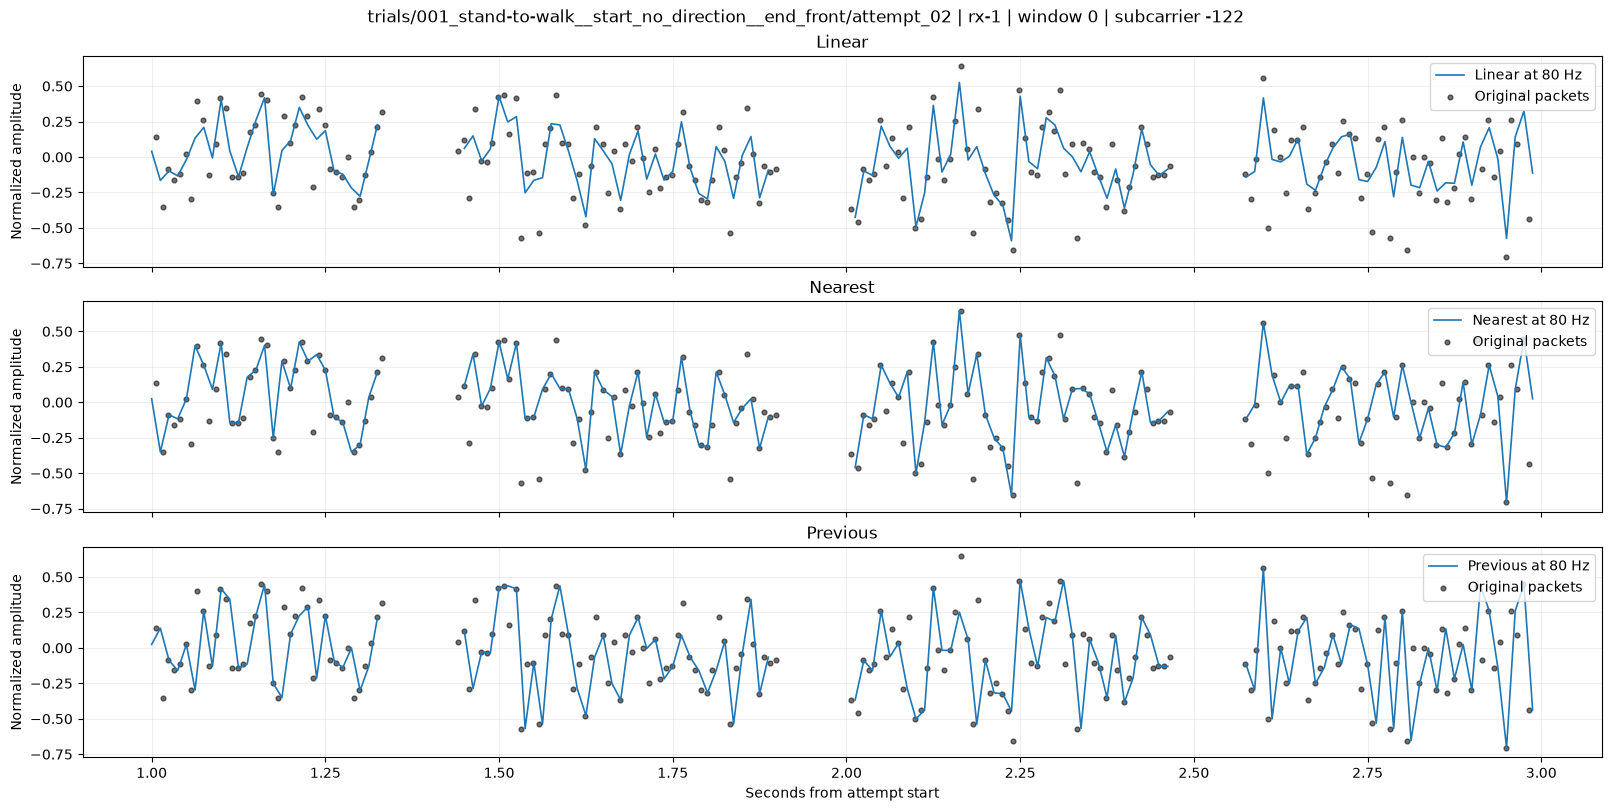

Valid resampled points: 134/160; maximum allowed gap: 25 ms.


In [23]:
import json
import matplotlib.pyplot as plt

# Select a row from the accepted recordings table and a window within it.
COMPARE_RECORDING_INDEX = 0
COMPARE_WINDOW_SECONDS = 2  # 2, 4, or 6
COMPARE_WINDOW_INDEX = 0
COMPARE_SUBCARRIER = None  # None selects a subcarrier with the most valid samples
COMPARE_MAX_GAP_SECONDS = 0.025

record = recordings.row(COMPARE_RECORDING_INDEX, named=True)
relative_path = Path(record["attempt_key"]) / f"{record['receiver_ids']}.npz"
window_root = PROJECT_ROOT / "data" / "interim" / "amplitude_windows_v1" / SESSION_ID
with np.load(OUTPUT_DIR / relative_path, allow_pickle=False) as src:
    source_times = src["time_seconds"]
    source_amplitude = src["amplitude"]
    source_valid = src["valid"]
    source_subcarriers = src["subcarriers"]
with np.load(window_root / f"{COMPARE_WINDOW_SECONDS}s" / relative_path, allow_pickle=False) as saved:
    grid = saved["time_seconds"][COMPARE_WINDOW_INDEX]
    saved_values = saved["amplitude"][COMPARE_WINDOW_INDEX]
    saved_valid = saved["valid"][COMPARE_WINDOW_INDEX]
    window_info = json.loads(str(saved["provenance_json"]))

if window_info["max_interpolation_gap_seconds"] != COMPARE_MAX_GAP_SECONDS:
    raise ValueError("Comparison gap must match the saved window's provenance.")
if COMPARE_SUBCARRIER is None:
    tone = int(np.argmax(saved_valid.sum(axis=0)))
    if not saved_valid[:, tone].any():
        raise ValueError("This window has no valid samples.")
else:
    match = np.flatnonzero(source_subcarriers == COMPARE_SUBCARRIER)
    if len(match) != 1:
        raise ValueError("Subcarrier is not present in this recording.")
    tone = int(match[0])

# Match the dataset's duplicate-timestamp policy: retain the last packet.
keep = np.r_[np.diff(source_times) != 0, True]
times = source_times[keep]
values = source_amplitude[keep, tone]
valid = source_valid[keep, tone] & np.isfinite(values)
right = np.minimum(np.searchsorted(times, grid, side="left"), len(times) - 1)
exact = times[right] == grid
left = np.maximum(right - 1, 0)
left[exact] = right[exact]
gap = times[right] - times[left]
supported = (exact | ((right > 0) & (gap <= COMPARE_MAX_GAP_SECONDS))) & valid[left] & valid[right]
weight = np.divide(grid - times[left], gap, out=np.zeros_like(grid), where=gap > 0)
methods = {
    "Linear": values[left] + weight * (values[right] - values[left]),
    "Nearest": np.where(weight <= 0.5, values[left], values[right]),
    "Previous": values[left].copy(),
}
for series in methods.values():
    series[~supported] = np.nan
np.testing.assert_array_equal(supported, saved_valid[:, tone])
np.testing.assert_allclose(methods["Linear"], saved_values[:, tone], equal_nan=True, rtol=1e-6, atol=1e-7)

fig, axes = plt.subplots(3, 1, figsize=(16, 8), sharex=True, sharey=True, layout="constrained")
original = valid & (times >= grid[0]) & (times <= grid[-1])
for ax, (name, series) in zip(axes, methods.items()):
    ax.plot(grid, series, label=f"{name} at 80 Hz", linewidth=1.2)
    ax.scatter(times[original], values[original], s=12, c="black", alpha=0.55, label="Original packets")
    ax.set_ylabel("Normalized amplitude")
    ax.set_title(name)
    ax.grid(alpha=0.2)
    ax.legend(loc="upper right")
axes[-1].set_xlabel("Seconds from attempt start")
fig.suptitle(f"{record['attempt_key']} | {record['receiver_ids']} | window {COMPARE_WINDOW_INDEX} | subcarrier {source_subcarriers[tone]}")
plt.show()
print(f"Valid resampled points: {supported.sum()}/{len(grid)}; maximum allowed gap: {COMPARE_MAX_GAP_SECONDS * 1000:g} ms.")
